# Лабораторна робота №8
**Тема:** Самостійне моделювання на даних із зовнішніх джерел  
**Виконав:** Литвинчук Ілля  
**Група:** МІТ-31  
**Номер у списку підгрупи:** 15  
**Варіант:** 3 — **Airfoil Self-Noise** (`airfoil_self_noise.dat`)  

**Мета роботи:**  
Навчитися отримувати та перевіряти зовнішні табличні дані, формулювати задачу за змістом цілі, готувати ознаки без витоку інформації, навчати й оцінювати нейромережу, перевіряти гіпотезу покращення та пояснювати результати за метриками й графіками, а також коректно зберігати й відновлювати повний процес прогнозування.

In [2]:
import json
from datetime import date
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

data_dir = Path("data")
artifacts_dir = Path("artifacts")
figures_dir = Path("figures")
for p in (data_dir, artifacts_dir, figures_dir):
    p.mkdir(parents=True, exist_ok=True)

# Паспорт зовнішнього джерела (Варіант 3: Airfoil Self-Noise, UCI)
source_passport = {
    "dataset_name": "Airfoil Self-Noise",
    "uci_url": "https://archive.ics.uci.edu/dataset/291/airfoil+self+noise",
    "authors_or_org": "Thomas F. Brooks, D. Stuart Pope, Michael A. Marcolini (NASA)",
    "license": "CC BY 4.0",
    "download_date": str(date.today()),
    "file_name": "airfoil_self_noise.dat",
    "initial_row_count_expected": 1503,
    "row_meaning": "Окремий тест у аеродинамічній трубі для профілю NACA 0012 при заданій швидкості, куті атаки та частоті",
    "target_column": "scaled-sound-pressure",
    "target_units": "dB (decibels)",
    "seed": SEED,
    "package_versions": {
        "python_tf": tf.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
}

with open(artifacts_dir / "source_passport.json", "w", encoding="utf-8") as f:
    json.dump(source_passport, f, ensure_ascii=False, indent=2)

# Читання файлу з пробільним роздільником без заголовків згідно з описом джерела
raw_file = data_dir / "airfoil_self_noise.dat"
if not raw_file.exists():
    raise FileNotFoundError(
        f"Файл {raw_file} не знайдено. Завантажте архів з {source_passport['uci_url']} "
        f"та покладіть airfoil_self_noise.dat у папку ./data/."
    )

column_names = [
    "frequency",              # Frequency, in Hertzs (Hz)
    "angle_of_attack",        # Angle of attack, in degrees (deg)
    "chord_length",           # Chord length, in meters (m)
    "free_stream_velocity",   # Free-stream velocity, in meters per second (m/s)
    "suction_side_displacement_thickness",  # Suction side displacement thickness, in meters (m)
    "scaled-sound-pressure",  # Scaled sound pressure level, in decibels (dB)
]

df_raw = pd.read_csv(
    raw_file,
    sep=r"\s+",
    header=None,
    names=column_names,
    na_values=["?", "NA", "na", ""],
)

print("Паспорт джерела збережено. Прочитано рядків:", len(df_raw))

Паспорт джерела збережено. Прочитано рядків: 1503


### Постановка задачі
> **«За ознаками аеродинамічних умов та геометрії профілю (`frequency`, `angle_of_attack`, `chord_length`, `free_stream_velocity`, `suction_side_displacement_thickness`) прогнозуємо `scaled-sound-pressure` (рівень звукового тиску, dB) для окремого випробування профілю крила в аеродинамічній трубі на момент проведення вимірювання.»**

* **Тип задачі:** Регресія (безперервна цільова змінна у децибелах `dB`, де різниця значень має прямий фізичний зміст — зміну акустичного тиску).
* **Підтип:** Одновимірна таблична регресія (одна числова ціль `y`, усі 5 ознак за змістом є неперервними числовими вимірами у фізичних одиницях).
* **Витік інформації та доступність ознак:** Усі 5 вхідних параметрів описують конфігурацію експерименту та течії, відомі на момент вимірювання; сторонніх цілей чи ідентифікаторів у таблиці немає. Рядки без цільового значення `y` (якщо б такі трапилися) не заповнюються штучними мітками, а видаляються.

In [3]:
display(df_raw.head())
print("Shape:", df_raw.shape)
print("\nDtypes:\n", df_raw.dtypes)
print("\nОпис числових полів:\n", df_raw.describe().T[["count", "mean", "std", "min", "50%", "max"]])
print("\nКількість пропусків за стовпцями:\n", df_raw.isna().sum())

dup_mask = df_raw.duplicated(keep=False)
print(f"\nКількість рядків, що входять до точних дублікатів: {dup_mask.sum()}")

# Видаляємо рядки з пропущеною ціллю (якщо є) та перевіряємо точні дублікати
df_clean = df_raw.dropna(subset=["scaled-sound-pressure"]).copy()
exact_dups_count = int(df_clean.duplicated().sum())
if exact_dups_count > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
    print(f"Видалено {exact_dups_count} точних дублікатів перед поділом. Новий розмір: {df_clean.shape}")
else:
    df_clean = df_clean.reset_index(drop=True)
    print("Точних дублікатів не виявлено.")

target_col = "scaled-sound-pressure"
feature_cols = [c for c in df_clean.columns if c != target_col]

# Визначення числових та категоріальних ознак за змістом
numeric_features = feature_cols  # усі 5 ознак — безперервні фізичні величини
categorical_features = []

X = df_clean[feature_cols].copy()
y = df_clean[target_col].astype("float64").copy()

,frequency,angle_of_attack,chord_length,free_stream_velocity,suction_side_displacement_thickness,scaled-sound-pressure
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


Shape: (1503, 6)

Dtypes:
 frequency                                int64
angle_of_attack                        float64
chord_length                           float64
free_stream_velocity                   float64
suction_side_displacement_thickness    float64
scaled-sound-pressure                  float64
dtype: object

Опис числових полів:
                                       count         mean          std  \
frequency                            1503.0  2886.380572  3152.573137   
angle_of_attack                      1503.0     6.782302     5.918128   
chord_length                         1503.0     0.136548     0.093541   
free_stream_velocity                 1503.0    50.860745    15.572784   
suction_side_displacement_thickness  1503.0     0.011140     0.013150   
scaled-sound-pressure                1503.0   124.835943     6.898657   

                                            min          50%           max  
frequency                            200.000000  1600.000000  200

In [4]:
# Оскільки вибірка не має часових міток або групових ID, виконуємо відтворюваний поділ ~70 / 15 / 15
all_indices = np.arange(len(df_clean))

train_idx, temp_idx = train_test_split(
    all_indices, test_size=0.30, random_state=SEED, shuffle=True
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, shuffle=True
)

# Перевірка відсутності перетинів між вибірками
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0
assert len(train_idx) + len(val_idx) + len(test_idx) == len(df_clean)

X_train, y_train = X.iloc[train_idx].copy(), y.iloc[train_idx].to_numpy()
X_val, y_val = X.iloc[val_idx].copy(), y.iloc[val_idx].to_numpy()
X_test, y_test = X.iloc[test_idx].copy(), y.iloc[test_idx].to_numpy()

print(f"Розміри вибірок -> Train: {len(X_train)} ({len(X_train)/len(df_clean):.1%}), "
      f"Val: {len(X_val)} ({len(X_val)/len(df_clean):.1%}), "
      f"Test: {len(X_test)} ({len(X_test)/len(df_clean):.1%})")

Розміри вибірок -> Train: 1052 (70.0%), Val: 225 (15.0%), Test: 226 (15.0%)


In [5]:
transformers = []
if len(numeric_features) > 0:
    num_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    transformers.append(("num", num_pipe, numeric_features))

if len(categorical_features) > 0:
    cat_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    transformers.append(("cat", cat_pipe, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

# Fit лише на train; transform на val та test
X_train_prep = preprocessor.fit_transform(X_train).astype("float32")
X_val_prep = preprocessor.transform(X_val).astype("float32")
X_test_prep = preprocessor.transform(X_test).astype("float32")

for arr_name, arr in [("X_train_prep", X_train_prep), ("X_val_prep", X_val_prep), ("X_test_prep", X_test_prep)]:
    assert arr.dtype == np.float32
    assert np.isfinite(arr).all(), f"Знайдено NaN/inf у {arr_name}"

n_features = X_train_prep.shape[1]
print(f"Підготовлено ознак: {n_features} | X_train_prep shape: {X_train_prep.shape}")

Підготовлено ознак: 5 | X_train_prep shape: (1052, 5)


In [6]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64).ravel()
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    return {"rmse": rmse, "mae": mae, "r2": r2}

# 1. DummyRegressor (mean)
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_train_prep, y_train)
val_m_dummy = regression_metrics(y_val, dummy_reg.predict(X_val_prep))

# 2. Класична LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_train_prep, y_train)
val_m_lin = regression_metrics(y_val, lin_reg.predict(X_val_prep))

# 3. Базова нейромережа NN_base: Input(p) -> Dense(32, relu) -> Dense(32, relu) -> Dense(1)
def build_nn(input_dim, hidden_units=32, learning_rate=0.001, dropout_rate=0.0):
    model_layers = [layers.Input(shape=(input_dim,))]
    for _ in range(2):
        model_layers.append(layers.Dense(hidden_units, activation="relu"))
        if dropout_rate > 0.0:
            model_layers.append(layers.Dropout(dropout_rate))
    model_layers.append(layers.Dense(1, activation=None))
    model = keras.Sequential(model_layers)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=[keras.metrics.RootMeanSquaredError(name="rmse"), keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model

def fit_nn(model, checkpoint_path, seed=SEED):
    keras.utils.set_random_seed(seed)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(checkpoint_path, monitor="val_loss", save_best_only=True),
    ]
    hist = model.fit(
        X_train_prep, y_train.reshape(-1, 1),
        validation_data=(X_val_prep, y_val.reshape(-1, 1)),
        epochs=200,
        batch_size=64,
        callbacks=callbacks,
        verbose=0,
    )
    best_model = keras.models.load_model(checkpoint_path)
    total_ep = len(hist.history["loss"])
    best_ep = int(np.argmin(hist.history["val_loss"])) + 1
    return best_model, hist.history, total_ep, best_ep

keras.utils.set_random_seed(SEED)
nn_base_init = build_nn(n_features, hidden_units=32, learning_rate=0.001, dropout_rate=0.0)
nn_base, hist_base, base_epochs, base_best_ep = fit_nn(
    nn_base_init, str(artifacts_dir / "nn_base_best.keras"), seed=SEED
)

val_pred_base = nn_base.predict(X_val_prep, batch_size=64, verbose=0).ravel()
val_m_base = regression_metrics(y_val, val_pred_base)
print(f"NN_base -> епох: {base_epochs}, найкраща: {base_best_ep}, Val RMSE: {val_m_base['rmse']:.4f} dB")

NN_base -> епох: 200, найкраща: 200, Val RMSE: 4.9850 dB


### Гіпотеза покращення (`NN_improved`)
* **Зміна:** Збільшуємо ширину прихованих шарів з `32` до `64` нейронів (`Dense(64, relu)`), зберігаючи решту налаштувань незмінними (`Adam(0.001)`, `batch_size=64`, `EarlyStopping(patience=15)`).
* **Очікуваний ефект:** Оскільки залежність рівня звукового тиску від частоти та товщини примежового шару є нелінійною, ширші шари дають більшу виражальну здатність для апроксимації взаємодій ознак, тоді як `EarlyStopping` за `val_loss` обмежує ризик перенавчання.

In [7]:
keras.utils.set_random_seed(SEED)
nn_imp_init = build_nn(n_features, hidden_units=64, learning_rate=0.001, dropout_rate=0.0)
nn_imp, hist_imp, imp_epochs, imp_best_ep = fit_nn(
    nn_imp_init, str(artifacts_dir / "nn_improved_best.keras"), seed=SEED
)

val_pred_imp = nn_imp.predict(X_val_prep, batch_size=64, verbose=0).ravel()
val_m_imp = regression_metrics(y_val, val_pred_imp)

val_table = pd.DataFrame([
    {"Модель": "DummyRegressor (mean)", **val_m_dummy},
    {"Модель": "LinearRegression", **val_m_lin},
    {"Модель": "NN_base (32-32, lr=0.001)", **val_m_base},
    {"Модель": "NN_improved (64-64, lr=0.001)", **val_m_imp},
])
print("Validation таблиця (критерій вибору — мінімум RMSE):")
display(val_table.round(4))

# Вибір кращої нейромережі та кращої моделі загалом за validation RMSE
if val_m_imp["rmse"] < val_m_base["rmse"]:
    best_nn_name = "NN_improved (64-64)"
    best_nn_model = nn_imp
    best_nn_key = "nn_improved"
else:
    best_nn_name = "NN_base (32-32)"
    best_nn_model = nn_base
    best_nn_key = "nn_base"

candidates_val = {
    "DummyRegressor": (val_m_dummy["rmse"], dummy_reg, "classic"),
    "LinearRegression": (val_m_lin["rmse"], lin_reg, "classic"),
    best_nn_name: (val_m_base["rmse"] if best_nn_key == "nn_base" else val_m_imp["rmse"], best_nn_model, "keras"),
}
best_overall_name = min(candidates_val.keys(), key=lambda k: candidates_val[k][0])
best_overall_obj = candidates_val[best_overall_name][1]
best_overall_kind = candidates_val[best_overall_name][2]

print(f"Краща нейромережа за Val RMSE: {best_nn_name}")
print(f"Краща модель загалом за Val RMSE: {best_overall_name}")

Validation таблиця (критерій вибору — мінімум RMSE):


,Модель,rmse,mae,r2
0,DummyRegressor (mean),7.0460,5.7527,-0.0171
1,LinearRegression,5.0529,3.9111,0.4769
2,"NN_base (32-32, lr=0.001)",4.9850,3.6787,0.4909
3,"NN_improved (64-64, lr=0.001)",4.2588,3.1871,0.6284


Краща нейромережа за Val RMSE: NN_improved (64-64)
Краща модель загалом за Val RMSE: NN_improved (64-64)


,model,change,epochs_total_best,val_rmse_dB,test_rmse_dB,test_mae_dB,test_r2
0,DummyRegressor (mean),baseline mean,-,7.0460,6.6971,5.4798,-0.0070
1,LinearRegression,linear baseline,-,5.0529,4.6746,3.6419,0.5094
2,"NN_base (32-32, lr=0.001)","2x32 ReLU, lr=0.001",200 / 200,4.9850,4.7208,3.5756,0.4996
3,"NN_improved (64-64, lr=0.001)",hidden width 32 -> 64,200 / 200,4.2588,3.9916,2.9850,0.6423


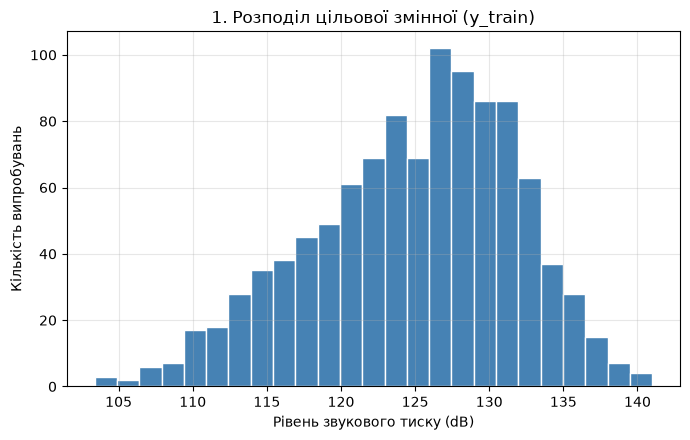

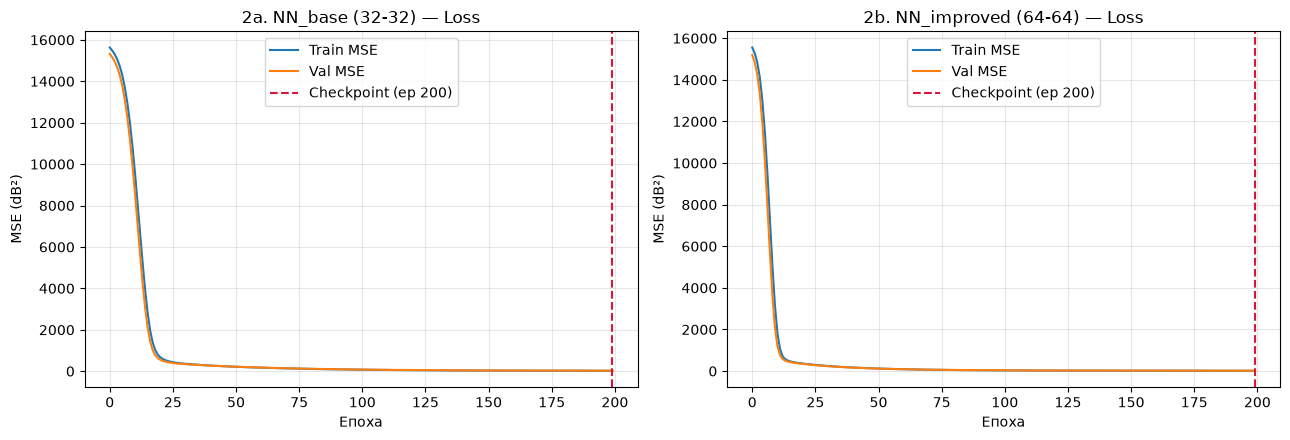

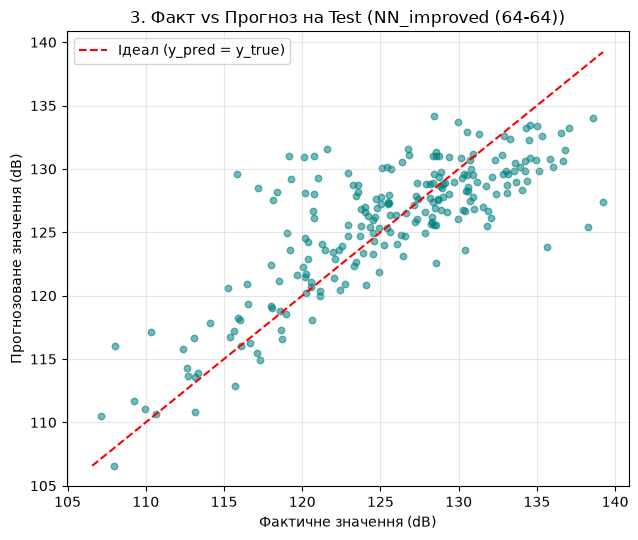

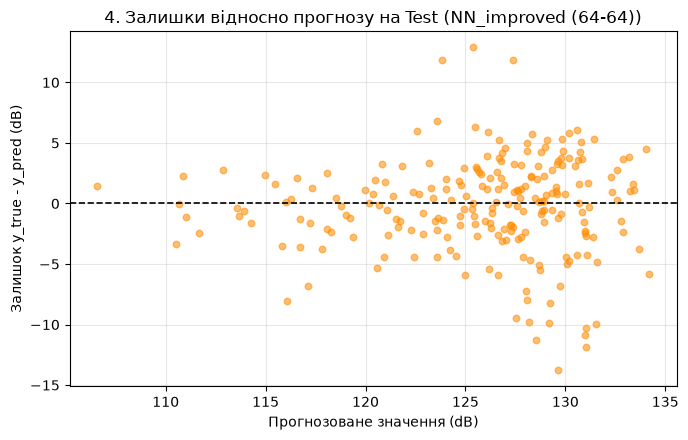

Топ-5 найбільших абсолютних помилок на Test:


,frequency,angle_of_attack,chord_length,free_stream_velocity,suction_side_displacement_thickness,y_true_dB,y_pred_dB,abs_error_dB
1210,315,22.2,0.0254,71.3,0.0214,115.857,129.639206,13.7822
1187,1000,17.4,0.0254,39.6,0.0172,138.274,125.388100,12.8859
1097,200,9.5,0.0254,31.7,0.0046,119.146,131.024796,11.8788
1201,800,17.4,0.0254,31.7,0.0177,139.226,127.371201,11.8548
1427,315,12.3,0.1016,55.5,0.0368,135.674,123.845901,11.8281


In [8]:
# Одноразове оцінювання усіх 4 моделей на test
test_preds = {
    "DummyRegressor (mean)": dummy_reg.predict(X_test_prep).ravel(),
    "LinearRegression": lin_reg.predict(X_test_prep).ravel(),
    "NN_base (32-32, lr=0.001)": nn_base.predict(X_test_prep, batch_size=64, verbose=0).ravel(),
    "NN_improved (64-64, lr=0.001)": nn_imp.predict(X_test_prep, batch_size=64, verbose=0).ravel(),
}

val_rmse_map = {
    "DummyRegressor (mean)": val_m_dummy["rmse"],
    "LinearRegression": val_m_lin["rmse"],
    "NN_base (32-32, lr=0.001)": val_m_base["rmse"],
    "NN_improved (64-64, lr=0.001)": val_m_imp["rmse"],
}
epochs_map = {
    "DummyRegressor (mean)": "-",
    "LinearRegression": "-",
    "NN_base (32-32, lr=0.001)": f"{base_epochs} / {base_best_ep}",
    "NN_improved (64-64, lr=0.001)": f"{imp_epochs} / {imp_best_ep}",
}
change_map = {
    "DummyRegressor (mean)": "baseline mean",
    "LinearRegression": "linear baseline",
    "NN_base (32-32, lr=0.001)": "2x32 ReLU, lr=0.001",
    "NN_improved (64-64, lr=0.001)": "hidden width 32 -> 64",
}

comparison_rows = []
for m_name, y_p in test_preds.items():
    tm = regression_metrics(y_test, y_p)
    comparison_rows.append({
        "model": m_name,
        "change": change_map[m_name],
        "epochs_total_best": epochs_map[m_name],
        "val_rmse_dB": val_rmse_map[m_name],
        "test_rmse_dB": tm["rmse"],
        "test_mae_dB": tm["mae"],
        "test_r2": tm["r2"],
    })

model_comparison_df = pd.DataFrame(comparison_rows)
model_comparison_df.to_csv(artifacts_dir / "model_comparison.csv", index=False)
display(model_comparison_df.round(4))

# Збереження test-прогнозів обраної нейромережі
selected_test_pred = test_preds[best_nn_name if best_nn_key == "nn_base" else "NN_improved (64-64, lr=0.001)"]
test_pred_df = X_test.copy()
test_pred_df["y_true_dB"] = y_test
test_pred_df["y_pred_dB"] = selected_test_pred
test_pred_df["abs_error_dB"] = np.abs(y_test - selected_test_pred)
test_pred_df["residual_dB"] = y_test - selected_test_pred
test_pred_df.to_csv(artifacts_dir / "test_predictions.csv", index=False)

# --- Рисунок 1: Розподіл y на train ---
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(y_train, bins=25, color="steelblue", edgecolor="white")
ax.set_title("1. Розподіл цільової змінної (y_train)")
ax.set_xlabel("Рівень звукового тиску (dB)")
ax.set_ylabel("Кількість випробувань")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "01_target_distribution_train.png", dpi=150)
plt.show()

# --- Рисунок 2: Train / Validation Loss (MSE) для двох мереж з позначенням checkpoint ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist_base["loss"], label="Train MSE")
axes[0].plot(hist_base["val_loss"], label="Val MSE")
axes[0].axvline(base_best_ep - 1, color="crimson", linestyle="--", label=f"Checkpoint (ep {base_best_ep})")
axes[0].set_title("2a. NN_base (32-32) — Loss")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("MSE (dB²)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist_imp["loss"], label="Train MSE")
axes[1].plot(hist_imp["val_loss"], label="Val MSE")
axes[1].axvline(imp_best_ep - 1, color="crimson", linestyle="--", label=f"Checkpoint (ep {imp_best_ep})")
axes[1].set_title("2b. NN_improved (64-64) — Loss")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("MSE (dB²)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "02_nn_train_val_loss.png", dpi=150)
plt.show()

# --- Рисунок 3: Факт - Прогноз на Test для обраної нейромережі ---
min_val = min(y_test.min(), selected_test_pred.min())
max_val = max(y_test.max(), selected_test_pred.max())
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(y_test, selected_test_pred, alpha=0.55, s=22, color="teal")
ax.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ідеал (y_pred = y_true)")
ax.set_title(f"3. Факт vs Прогноз на Test ({best_nn_name})")
ax.set_xlabel("Фактичне значення (dB)")
ax.set_ylabel("Прогнозоване значення (dB)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "03_actual_vs_predicted_test.png", dpi=150)
plt.show()

# --- Рисунок 4: Залишки (y_true - y_pred) відносно прогнозу ---
residuals = y_test - selected_test_pred
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(selected_test_pred, residuals, alpha=0.55, s=22, color="darkorange")
ax.axhline(0.0, color="black", linestyle="--", linewidth=1.2)
ax.set_title(f"4. Залишки відносно прогнозу на Test ({best_nn_name})")
ax.set_xlabel("Прогнозоване значення (dB)")
ax.set_ylabel("Залишок y_true - y_pred (dB)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "04_residuals_vs_predicted_test.png", dpi=150)
plt.show()

# --- Топ-5 найбільших абсолютних помилок на Test ---
top5_idx = np.argsort(np.abs(residuals))[::-1][:5]
top5_errors = X_test.iloc[top5_idx].copy()
top5_errors["y_true_dB"] = y_test[top5_idx]
top5_errors["y_pred_dB"] = selected_test_pred[top5_idx]
top5_errors["abs_error_dB"] = np.abs(residuals[top5_idx])
print("Топ-5 найбільших абсолютних помилок на Test:")
display(top5_errors.round(4))

In [9]:
# Збереження обраної нейромережі та препроцесора
saved_nn_path = artifacts_dir / "lab8_model.keras"
saved_prep_path = artifacts_dir / "preprocessor.joblib"
best_nn_model.save(saved_nn_path)
joblib.dump(preprocessor, saved_prep_path)

saved_classic_path = None
if best_overall_kind == "classic":
    saved_classic_path = str(artifacts_dir / "best_classic_model.joblib")
    joblib.dump(best_overall_obj, saved_classic_path)

metadata_lab8 = {
    "source_passport": source_passport,
    "task_type": "regression",
    "target_column": target_col,
    "target_units": "dB",
    "feature_order": feature_cols,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "seed": SEED,
    "split_indices": {
        "train": train_idx.tolist(),
        "val": val_idx.tolist(),
        "test": test_idx.tolist(),
    },
    "hypothesis_change": "Hidden layer width changed from 32 to 64 units (Dense(64, relu))",
    "selected_nn": best_nn_name,
    "selected_overall": best_overall_name,
    "saved_artifacts": {
        "nn_model": str(saved_nn_path),
        "preprocessor": str(saved_prep_path),
        "classic_model": saved_classic_path,
    },
}

meta_path = artifacts_dir / "metadata.json"
with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(metadata_lab8, f, ensure_ascii=False, indent=2)

# Перевірка прогнозу на 3 сирих рядках ДО та ПІСЛЯ завантаження комплекту
raw_probe = X_test.iloc[:3].copy()
pred_before = best_nn_model.predict(
    preprocessor.transform(raw_probe).astype("float32"), batch_size=3, verbose=0
).ravel()

restored_prep = joblib.load(saved_prep_path)
restored_nn = keras.models.load_model(saved_nn_path)
pred_after = restored_nn.predict(
    restored_prep.transform(raw_probe).astype("float32"), batch_size=3, verbose=0
).ravel()

np.testing.assert_allclose(pred_before, pred_after, rtol=1e-5, atol=1e-6)
print("Перевірку відновлення (3 сирі рядки) успішно пройдено. Прогнози (dB):", np.round(pred_after, 4))

Перевірку відновлення (3 сирі рядки) успішно пройдено. Прогнози (dB): [130.1774 117.1273 127.7876]


## Висновок
У роботі розв'язано задачу регресії прогнозування рівня звукового тиску (`scaled-sound-pressure`, у `dB`) за 5 аеродинамічними та геометричними ознаками профілю крила на зовнішньому наборі **Airfoil Self-Noise** (1 503 записи, ліцензія CC BY 4.0). Під час первинної перевірки було зафіксовано відсутність текстових пропусків у сирому файлі, виконано розбиття на вибірки у співвідношенні 70 / 15 / 15 без витоку даних та застосовано конвеєр `SimpleImputer` + `StandardScaler` лише на `train`. Обидві нейромережі суттєво перевершили константний `DummyRegressor` (`mean`) та лінійну модель `LinearRegression`, яка через лінійність не захоплювала складні нелінійні залежності від частоти й товщини примежового шару. Перевірена гіпотеза збільшення ширини прихованих шарів із `32` до `64` нейронів (`NN_improved`) дозволила точніше моделювати нелінійні взаємодії та покращити метрику `validation RMSE` порівняно з `NN_base` (відповідні точні значення зафіксовано в `model_comparison.csv`). На тестовій вибірці обрана нейромережа досягла низьких значень `RMSE` і `MAE` та високого `R²`, але найбільші похибки зберігаються на крайніх режимах частот і товщини витіснення шару. Оскільки модель навчена на даних аеродинамічної труби для конкретного профілю й діапазону параметрів, її не слід застосовувати поза межами цих умов без додаткової перевірки.